<a href="https://colab.research.google.com/github/Vykhrystenko/ML_FIT_3-9_Vykhrystenko/blob/main/%D0%9B%D0%A0%E2%84%964_%D0%92%D0%B8%D1%85%D1%80%D0%B8%D1%81%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_3_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import os

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
)

In [2]:
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))

display(df.head())

Using Colab cache for faster access to the 'car-price-prediction' dataset.


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


**car_ID**: Унікальний ідентифікатор (порядковий номер автомобіля в базі).

**symboling**: Страховий рейтинг ризику (-3 до +3); позитивні значення вказують на більш спортивні/ризиковані авто.

**CarName**: Повна назва автомобіля, що складається з марки та моделі.

**fueltype**: Тип палива, яке використовує двигун (бензин або дизель).

**aspiration**: Тип наддуву двигуна (звичайний атмосферний чи турбований).

**doornumber**: Кількість дверей у автомобіля (двох- або чотиридверний).

**carbody**: Тип кузова автомобіля (наприклад, седан, хетчбек, універсал).

**drivewheel**: Тип приводу коліс (передній, задній або повний).

**enginelocation**: Розташування двигуна в кузові (спереду чи ззаду).

**wheelbase**: Колісна база — відстань між центрами передніх і задніх осей.

**carlength, carwidth, carheight**: Габаритні розміри автомобіля: довжина, ширина та висота.

**curbweight**: Споряджена маса повністю заправленого автомобіля без пасажирів.

**enginetype**: Конфігурація та тип двигуна (наприклад, ohc, ohcv).

**cylindernumber**: Кількість циліндрів у двигуні.

**enginesize**: Робочий об'єм двигуна.

**fuelsystem**: Тип паливної системи (карбюратор, інжектор тощо).

**biorerato**: Діаметр циліндра двигуна.

**stroke**: Хід поршня всередині циліндра.

**compressionratio**: Ступінь стиску паливо-повітряної суміші.

**horsepower**: Потужність двигуна в кінських силах.

**peakrpm**: Максимальна кількість обертів двигуна за хвилину.

**citympg**: Паливна економічність у міському циклі (миль на галолон).

**highwaympg**: Паливна економічність на трасі (миль на галолон).

**price**: Ціна автомобіля — цільова змінна, яку намагається передбачити модель.



In [3]:
print("Розмір датасету:", df.shape)
df.info()

Розмір датасету: (205, 26)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize       

In [4]:
df.dtypes

,0
car_ID,int64
symboling,int64
CarName,object
fueltype,object
aspiration,object
doornumber,object
carbody,object
drivewheel,object
enginelocation,object
wheelbase,float64


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [5]:
print("Кількість пропущених значень:")
display(df.isna().sum().sort_values(ascending=False))

print("Повні дублікати:", df.duplicated().sum())
print(
    "Дублікати без урахування car_ID:",
    df.drop(columns="car_ID").duplicated().sum()
)

Кількість пропущених значень:


,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


Повні дублікати: 0
Дублікати без урахування car_ID: 0


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [6]:
df['CarName'].value_counts()

,count
CarName,
peugeot 504,6
toyota corolla,6
toyota corona,6
subaru dl,4
mitsubishi outlander,3
...,...
volkswagen super beetle,1
volkswagen rabbit custom,1
volvo 245,1


In [7]:
ids = df["car_ID"].copy()

df_model = df.copy()
df_model["brand"] = (
    df_model["CarName"]
        .str.lower()
        .str.split()
        .str[0]
        .replace({
            "maxda": "mazda",
            "porcshce": "porsche",
            "toyouta": "toyota",
            "vokswagen": "volkswagen",
            "vw": "volkswagen",
        })
)
df_model = df_model.drop(columns=["car_ID", "CarName"])

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


,skewness
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


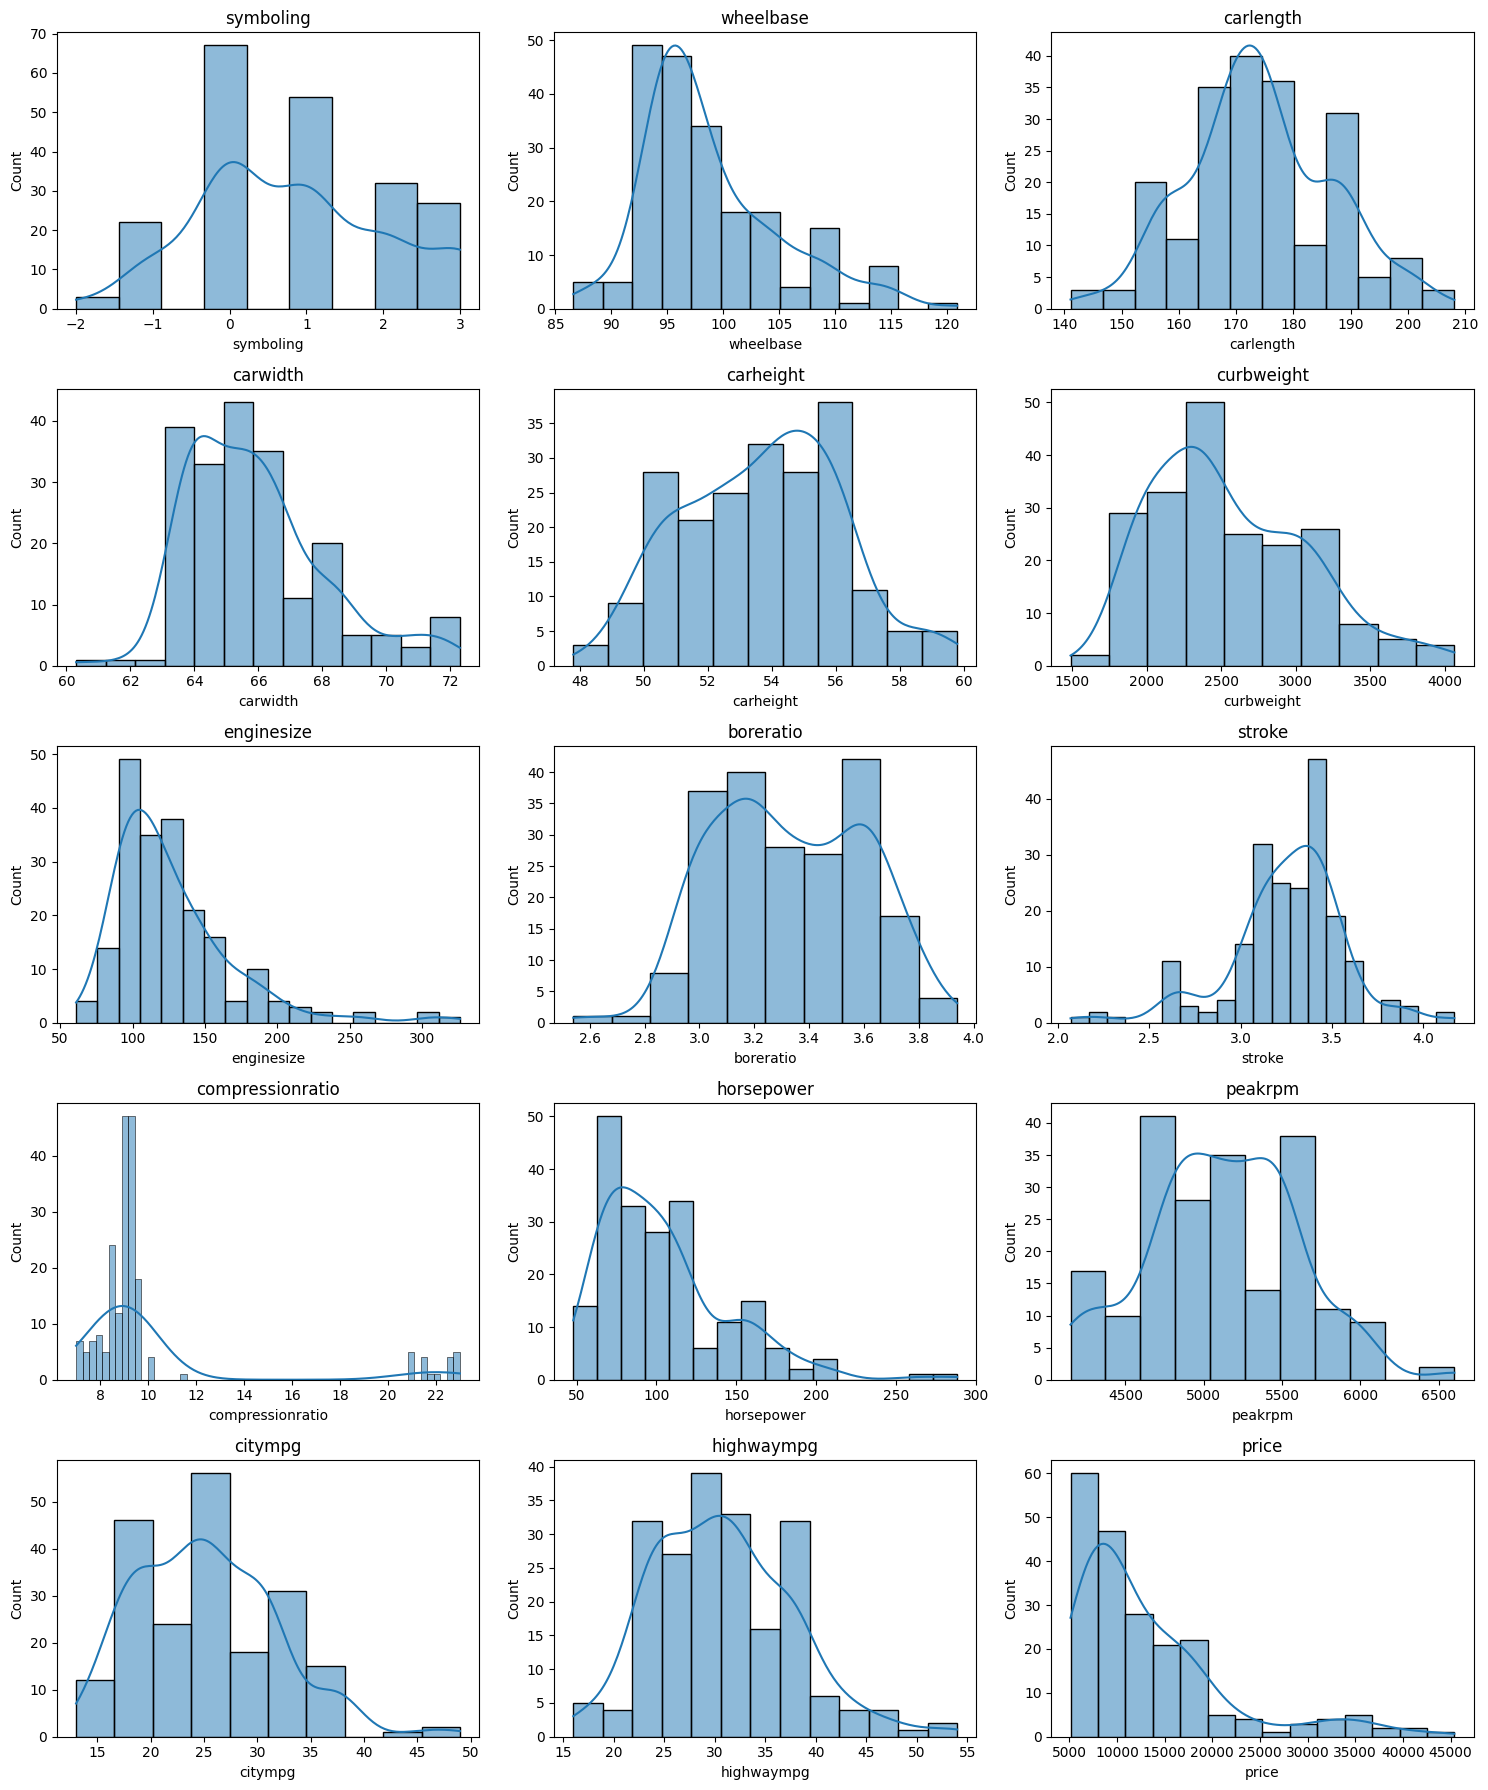

In [8]:
numeric_initial = df_model.select_dtypes(include=np.number).columns
skew_initial = df_model[numeric_initial].skew().sort_values(key=np.abs, ascending=False)

display(skew_initial.to_frame("skewness"))

n_cols = 3
n_rows = int(np.ceil(len(numeric_initial) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.6 * n_rows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, numeric_initial):
    sns.histplot(df_model[col], kde=True, ax=ax)
    ax.set_title(col)
for ax in axes[len(numeric_initial):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [9]:

X = df_model.drop(columns="price")

y = df_model["price"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

id_train = ids.loc[X_train.index]
id_test = ids.loc[X_test.index]

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (164, 24) Test: (41, 24)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [10]:
continuous_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c != "symboling"
]

q1 = X_train[continuous_cols].quantile(0.25)

q3 = X_train[continuous_cols].quantile(0.75)

iqr = q3 - q1

lower_bounds = q1 - 1.5 * iqr

upper_bounds = q3 + 1.5 * iqr

outlier_counts = (
    (X_train[continuous_cols].lt(lower_bounds)) |
    (X_train[continuous_cols].gt(upper_bounds))
).sum().sort_values(ascending=False)

display(outlier_counts.to_frame("potential_outliers_train"))

X_train = X_train.copy()
X_test = X_test.copy()

X_train[continuous_cols] = X_train[continuous_cols].clip(
    lower=lower_bounds,
    upper=upper_bounds,
    axis=1
)

X_test[continuous_cols] = X_test[continuous_cols].clip(
    lower=lower_bounds,
    upper=upper_bounds,
    axis=1
)

,potential_outliers_train
compressionratio,20
stroke,16
carwidth,10
horsepower,7
enginesize,7
wheelbase,6
peakrpm,2
highwaympg,1
boreratio,1
curbweight,0


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


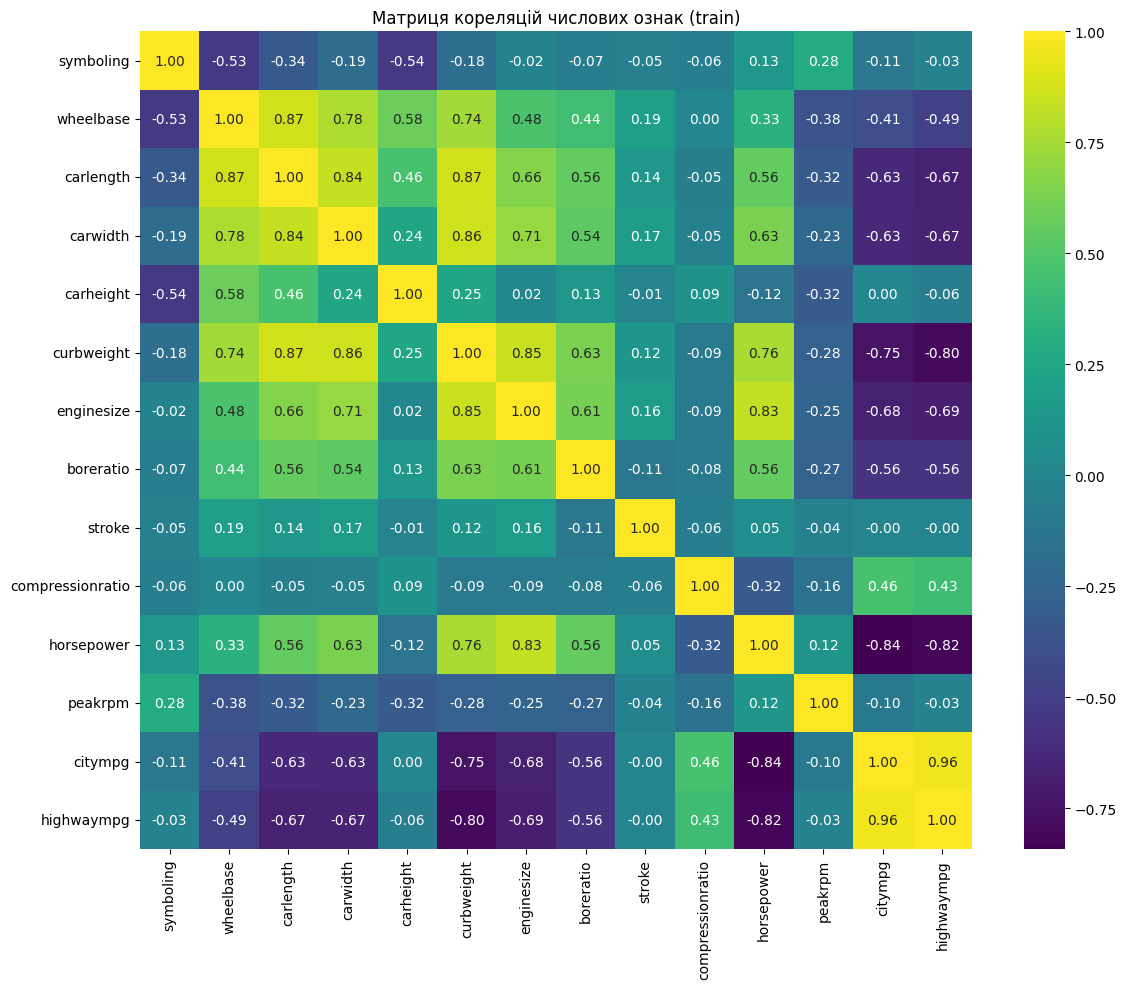

Сильно корельовані пари (|r| > 0.85):
wheelbase - carlength: 0.867
carlength - curbweight: 0.866
carwidth - curbweight: 0.858
citympg - highwaympg: 0.964
Ознаки для видалення: ['carlength', 'carwidth', 'citympg', 'wheelbase']


In [11]:
numeric_train_cols = X_train.select_dtypes(include=np.number).columns
corr = X_train[numeric_train_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="viridis", cbar=True)
plt.title("Матриця кореляцій числових ознак (train)")
plt.tight_layout()
plt.show()

target_corr = pd.concat(
    [
        X_train[numeric_train_cols],
        y_train.rename("price")
    ],
    axis=1
).corr(numeric_only=True)["price"].abs()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

pairs = []
for col in upper.columns:
    for row in upper.index[upper[col] > 0.85]:
        pairs.append(
            (row, col, upper.loc[row, col])
        )

features_to_drop = set()
for a, b, r in pairs:
    if target_corr[a] < target_corr[b]:
        features_to_drop.add(a)
    else:
        features_to_drop.add(b)

print("Сильно корельовані пари (|r| > 0.85):")
for a, b, r in pairs:
    print(f"{a} - {b}: {r:.3f}")

print("Ознаки для видалення:", sorted(features_to_drop))

X_train = X_train.drop(
    columns=list(features_to_drop)
)
X_test = X_test.drop(
    columns=list(features_to_drop)
)

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [12]:
continuous_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c != "symboling"
]

ordinal_numeric_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c == "symboling"
]

categorical_cols = (
    X_train
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

numeric_pipeline = Pipeline(steps=[

    ("power", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler()),
])
ordinal_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[

    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )),
])

preprocessor = ColumnTransformer(
    transformers=[

        ("continuous", numeric_pipeline, continuous_cols),

        ("ordinal", ordinal_pipeline, ordinal_numeric_cols),

        ("categorical", categorical_pipeline, categorical_cols),
    ],

    remainder="drop",

    verbose_feature_names_out=False,
)

num_check = clone(numeric_pipeline)

num_train_transformed = pd.DataFrame(
    num_check.fit_transform(
        X_train[continuous_cols]
    ),
    columns=continuous_cols,
    index=X_train.index,
)

skewness_after = (
    num_train_transformed
    .skew()
    .sort_values(
        key=np.abs,
        ascending=False
    )
)

display(
    skewness_after.to_frame("skewness_after")
)

,skewness_after
horsepower,0.066280
curbweight,0.049894
enginesize,0.044834
stroke,0.015846
highwaympg,-0.012188
boreratio,-0.005941
carheight,-0.005170
compressionratio,0.004872
peakrpm,-0.003589


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [13]:
models = {
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(random_state=42, max_iter=10000),
    "Ridge": Ridge(random_state=42),
    "SVR": SVR()
}

results = []

for name, model in models.items():
    # Об'єднуємо препроцесор та модель у єдиний pipeline
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Навчання моделі
    pipeline.fit(X_train, y_train)

    # Прогнозування на тестовій вибірці
    y_pred = pipeline.predict(X_test)

    # Обчислення метрик
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results.append({
        "Model": name,
        "R^2": r2,
        "MAE": mae,
        "MSE": mse,
        "MAPE, %": mape
    })

# Формування та сортування DataFrame за спаданням R^2
results_df = pd.DataFrame(results).sort_values(by="R^2", ascending=False).reset_index(drop=True)
display(results_df)

,Model,R^2,MAE,MSE,"MAPE, %"
0,Random Forest,0.954225,1351.187085,3.613633e+06,9.856585
1,Gradient Boosting,0.930420,1727.403684,5.492942e+06,12.050186
2,Linear Regression,0.879431,2156.098245,9.518236e+06,16.376447
3,Lasso,0.878234,2105.214295,9.612671e+06,15.133568
4,Ridge,0.853789,2367.223583,1.154249e+07,18.193087
5,SVR,-0.099732,5696.776966,8.681724e+07,36.027666


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [16]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(random_state=42),
    "Lasso Regression": Lasso(random_state=42, max_iter=10000),
    "Random Forest Regressor": RandomForestRegressor(random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42),
    "Support Vector Regressor (SVR)": SVR()
}

model_pipelines = {}
results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    model_pipelines[name] = pipeline

    y_pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results.append({
        "Model": name,
        "R^2": r2,
        "MAE": mae,
        "MSE": mse,
        "MAPE, %": mape
    })

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [17]:

results_df = results_df.sort_values(by="R^2", ascending=False).reset_index(drop=True)

display(results_df)

,Model,R^2,MAE,MSE,"MAPE, %"
0,Random Forest Regressor,0.954225,1351.187085,3.613633e+06,9.856585
1,Gradient Boosting Regressor,0.930420,1727.403684,5.492942e+06,12.050186
2,Linear Regression,0.879431,2156.098245,9.518236e+06,16.376447
3,Lasso Regression,0.878234,2105.214295,9.612671e+06,15.133568
4,Ridge Regression,0.853789,2367.223583,1.154249e+07,18.193087
5,Support Vector Regressor (SVR),-0.099732,5696.776966,8.681724e+07,36.027666


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Класифікаційні моделі (наприклад, Logistic Regression) призначені для прогнозування дискретних класів або категорій (наприклад, визначити, чи належить автомобіль до бюджетного чи дорогого сегмента). Ціна автомобіля (price) є неперервною кількісною величиною, яка може набувати будь-яких значень у певному діапазоні. Класифікація не здатна прогнозувати точне числове значення ціни.

Прогнозування ціни автомобіля належить до задачі регресії . Використані в роботі моделі розроблені спеціально для задач регресії, оскільки їхній математичний апарат націлений на мінімізацію відхилень числових прогнозів від реальних значень цільової змінної.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


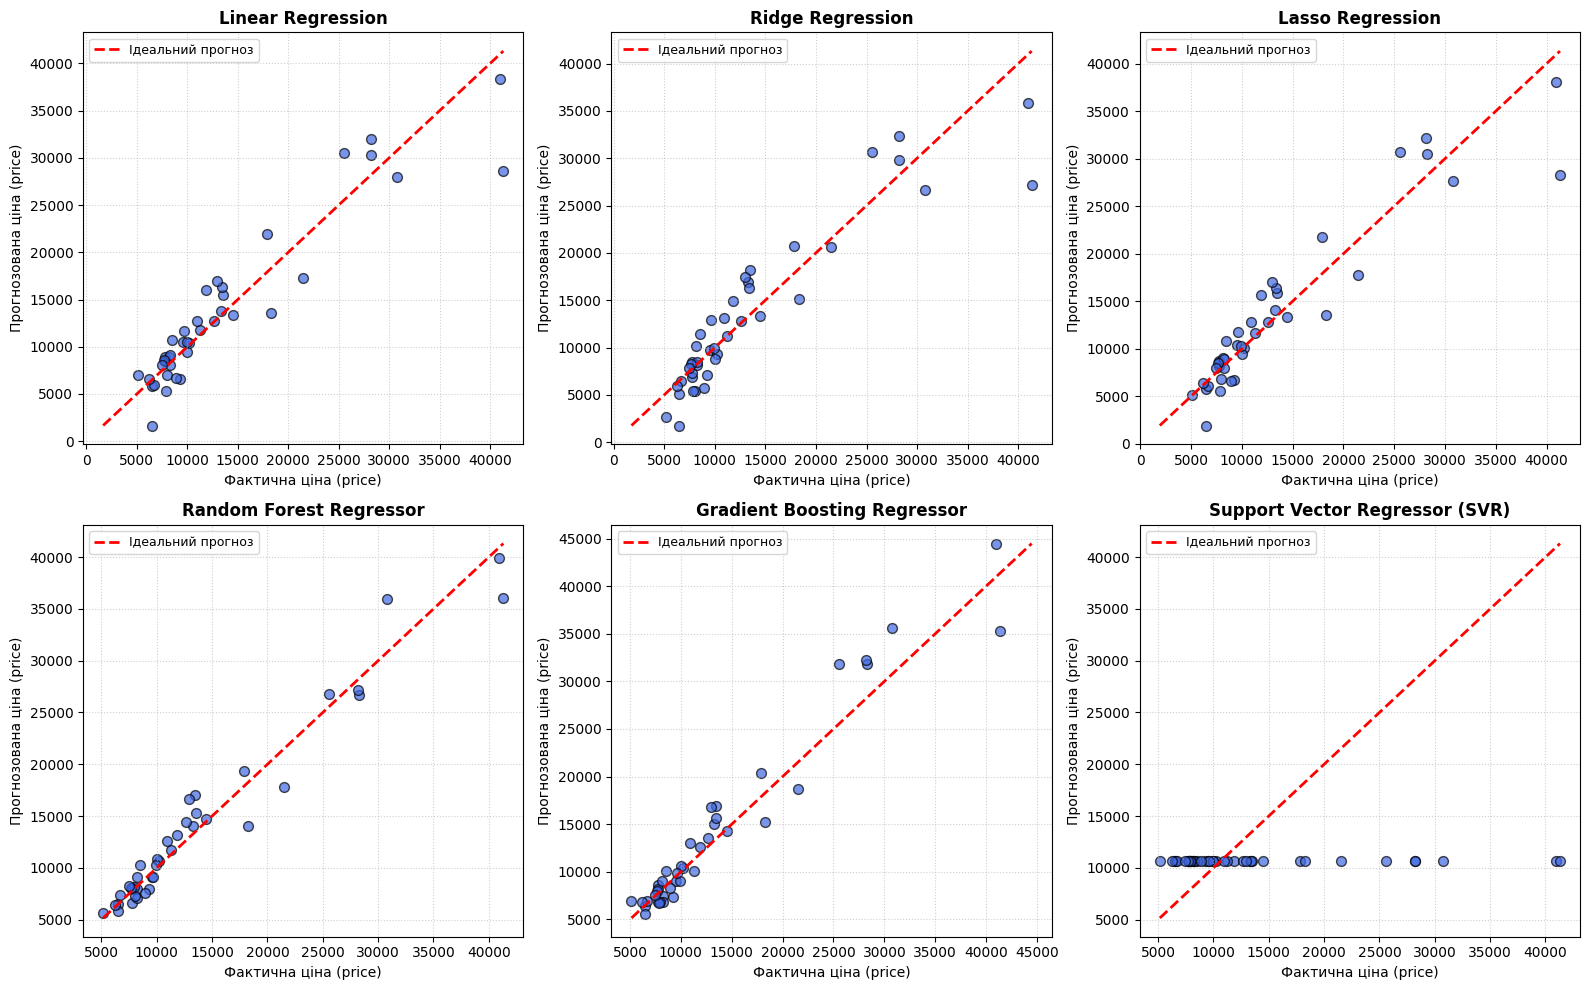

In [18]:

n_models = len(model_pipelines)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()

for idx, (name, pipeline) in enumerate(model_pipelines.items()):
    ax = axes[idx]
    y_pred = pipeline.predict(X_test)

    ax.scatter(y_test, y_pred, alpha=0.7, color='royalblue', edgecolor='k', s=50)

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ідеальний прогноз')

    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_xlabel('Фактична ціна (price)', fontsize=10)
    ax.set_ylabel('Прогнозована ціна (price)', fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left', fontsize=9)

for idx in range(n_models, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

Точки знаходяться близько до лінії, з мінімальним розсіюванням у Random Forest та Gradient Boosting. Лінійні моделі мають помірні відхилення (особливо для дорожчих авто), а SVR демонструє повну похибку та неадекватний розподіл.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [19]:

sample_X_test = X_test.sample(n=10, random_state=42)
sample_y_test = y_test.loc[sample_X_test.index]
sample_ids = id_test.loc[sample_X_test.index]

rf_pipeline = model_pipelines["Random Forest Regressor"]
sample_y_pred = rf_pipeline.predict(sample_X_test)

results_10 = pd.DataFrame({
    "car_ID": sample_ids.values,
    "Фактична ціна": sample_y_test.values,
    "Прогнозована ціна": sample_y_pred,
    "Абсолютна помилка": np.abs(sample_y_test.values - sample_y_pred),
    "Абсолютна відсоткова помилка, %": (np.abs(sample_y_test.values - sample_y_pred) / sample_y_test.values) * 100
}).reset_index(drop=True)

display(results_10)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,"Абсолютна відсоткова помилка, %"
0,26,6692.0,7355.275000,663.275000,9.911461
1,176,9988.0,10883.896667,895.896667,8.969730
2,148,10198.0,10661.076667,463.076667,4.540858
3,17,41315.0,36048.880000,5266.120000,12.746266
4,69,28248.0,26697.370000,1550.630000,5.489344
5,147,7463.0,8272.670000,809.670000,10.849122
6,144,9960.0,10238.063333,278.063333,2.791801
7,85,14489.0,14738.950000,249.950000,1.725102
8,195,12940.0,16647.240000,3707.240000,28.649459
9,160,7788.0,7915.580000,127.580000,1.638161


Модель Random Forest забезпечує високу точність (похибка більшості авто <5%), але на дорогих екземплярах (авто 195, 17) похибка зростає до 12-28% через згладжування екстремальних значень.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Протягом виконання даної лабораторної роботи було порівняно шість різних регресійних моделей, які охоплюють як лінійні алгоритми, так і ансамблі дерев рішень та опорні вектори.

Аналіз ключових метрик (R^2, MAE, MSE та MAPE) показав суттєву відмінність у їхній здатності адекватно відтворювати нелінійні залежності у даних.

Найвищу ефективність серед усіх досліджених алгоритмів продемонструвала модель Random Forest Regressor, яка забезпечила найбільший коефіцієнт детермінації та найменші показники похибок на тестовій вибірці.

Величина похибок коливається від мінімальних значень для типових комплектацій автомобілів до помірного зростання на екстремальних значеннях, що пов'язано з особливостями роботи ансамблів дерев рішень.

Ознаки потенційного перенавчання контролювалися завдяки використанню крос-валідаційного підходу, єдиного пайплайну передобробки та незалежної тестової вибірки, на якій метрики залишаються на високому рівні.

Попередня обробка даних, зокрема логарифмування/трансформація числових ознак для зменшення асиметрії, видалення мультикореляційних ознак та правильне кодування категорій, суттєво покращила стабільність і якість прогнозів усіх моделей.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
